# Few-shot Universal Dependency parsing with LLMs

Baseline experiment for the multilingual UD parsing project: how much dependency-parsing ability does a pretrained LLM have **without weight updates**, given $N \in \{0,3,5,10\}$ demonstrations in the prompt?

**Pipeline**
1. Load UD treebanks (demo pool from train, else dev, else held-out part of test).
2. Linearize trees into the U-DepPLLaMA bracketed format, e.g. `[ROOT[NSUBJ[He]][AUX[was]][recognized]...]`.
3. Build completion-style prompts (identical instruction, only demonstrations vary; demonstrations are nested across $N$ and shared across models).
4. Greedy decoding with a 4-bit quantized model.
5. Parse the output back to heads and relations; recover as in the paper (reorder, attach missing words to root); invalid output counts as all wrong.
6. Score UAS, LAS, F1, invalid-output rate; aggregate over seeds; rank models.

**Metrics.** With $n_{\text{gold}}$ gold words, $n_{\text{sys}}$ system words, and $c_{\text{head}}$, $c_{\text{las}}$ the number of words with correct head, or correct head and label:

$$\mathrm{UAS}=\frac{c_{\text{head}}}{n_{\text{gold}}},\qquad \mathrm{LAS}=\frac{c_{\text{las}}}{n_{\text{gold}}},\qquad P=\frac{c_{\text{las}}}{n_{\text{sys}}},\; R=\frac{c_{\text{las}}}{n_{\text{gold}}},\; F_1=\frac{2PR}{P+R}$$

Scores are micro-averaged over words. Label comparison ignores UD subtypes (`nsubj:pass` $\to$ `nsubj`), as in the CoNLL shared-task LAS.

## 1. Setup

In [98]:
!pip install -q conllu "transformers>=4.44" accelerate bitsandbytes pandas matplotlib


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [99]:
import os, re, json, random, math, glob, time, urllib.request
from collections import Counter, defaultdict
import numpy as np, pandas as pd, torch, conllu

# ---------------- CONFIG ----------------
CFG = dict(
    # name -> HF id. VERIFY ids/access (Llama-2 and Aya are gated: accept the license and set HF_TOKEN).
    models = {
        "llama-3.1":      r"C:\Users\alexa\Desktop\TUM\NLP\llama-3.1-8b",
        "aya-expanse-8b": "CohereLabs/aya-expanse-8b",
        "bolmo-7b":       "allenai/Bolmo-7B",
    },
    run_models   = ["llama-3.1"],            # start with one; add the others later
    treebanks    = ["en_ewt", "fo_oft"],
    shots        = [0, 3, 10],
    seeds        = [0],                # demonstration seeds (0-shot is run once)
    mode         = "gold",                   # "gold": gold tokenization | "raw": raw text input
    n_eval       = 200,                      # eval sentences per treebank (fixed random subset)
    max_eval_words = 40,
    max_demo_words = 25,
    batch_size   = 8,
    demo_source  = {},                       # ablation, e.g. {"bar_maibaam": "de_gsd"} = German demos for Bavarian
    held_out_demos = 50,                     # demo pool size carved from test when a treebank has no train/dev
    strip_subtypes = True,
    prompt       = "v2",                     # "v1": original instruction | "v2": glossary + conventions + worked example, subtype-free demos
    constraint   = "grammar",                # "none" | "grammar" (tree grammar + 37 UD labels) | "grammar+words" (also: each gold word exactly once; gold mode only)
    out_dir      =  "results",    # set to a Drive path to survive disconnects
)
# resource level (used for weighting in the final ranking)
LEVEL = dict(en_ewt="HR", en_gum="HR", de_gsd="HR", de_hdt="HR",
             af_afribooms="MR", hy_armtdp="MR", fo_farpahc="LR", fo_oft="LR", bar_maibaam="LR")
WEIGHT = dict(HR=1.0, MR=1.5, LR=2.0)

# (repo, file prefix)
TREEBANKS = {
    "en_ewt":       ("UD_English-EWT", "en_ewt"),
    "en_gum":       ("UD_English-GUM", "en_gum"),
    "de_gsd":       ("UD_German-GSD", "de_gsd"),
    "de_hdt":       ("UD_German-HDT", "de_hdt"),
    "af_afribooms": ("UD_Afrikaans-AfriBooms", "af_afribooms"),
    "fo_farpahc":   ("UD_Faroese-FarPaHC", "fo_farpahc"),
    "fo_oft":       ("UD_Faroese-OFT", "fo_oft"),
    "bar_maibaam":  ("UD_Bavarian-MaiBaam", "bar_maibaam"),
    "hy_armtdp":    ("UD_Armenian-ArmTDP", "hy_armtdp"),
}
DATA_DIR = "data/ud_data"
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(CFG["out_dir"], exist_ok=True)

In [100]:
from pathlib import Path
import os
f = Path("HF_TOKEN")
if f.exists(): os.environ["HF_TOKEN"] = f.read_text().strip()

## 2. Data

In [101]:
def fetch(repo, prefix, split):
    path = f"{DATA_DIR}/{prefix}-ud-{split}.conllu"
    if not (os.path.exists(path) and os.path.getsize(path) > 0):
        url = f"https://raw.githubusercontent.com/UniversalDependencies/{repo}/master/{prefix}-ud-{split}.conllu"
        try: urllib.request.urlretrieve(url, path)
        except Exception: 
            if os.path.exists(path): os.remove(path)
            return None
    return path

def clean(form):
    # brackets would break the tree format; spaces break word alignment
    return str(form).replace("[", "{").replace("]", "}").replace(" ", "_")

def read_conllu(path):
    sents = []
    with open(path, encoding="utf8") as f:
        for tl in conllu.parse_incr(f):
            toks = [t for t in tl if isinstance(t["id"], int)]      # drop multiword/empty nodes
            if not toks or [t["id"] for t in toks] != list(range(1, len(toks) + 1)): continue
            heads = [t["head"] for t in toks]
            if any(h is None for h in heads) or sum(h == 0 for h in heads) != 1: continue
            forms = [clean(t["form"]) for t in toks]
            sents.append(dict(id=tl.metadata.get("sent_id"),
                              text=tl.metadata.get("text", " ".join(forms)),
                              forms=forms, heads=heads,
                              deprels=[t["deprel"] for t in toks]))
    return sents

DATA = {}
def load_treebank(name):
    repo, prefix = TREEBANKS[name]
    paths = {s: fetch(repo, prefix, s) for s in ["train", "dev", "test"]}
    test = read_conllu(paths["test"])
    if paths["train"]:   pool, src = read_conllu(paths["train"]), "train"
    elif paths["dev"]:   pool, src = read_conllu(paths["dev"]), "dev"
    else:                # no train/dev: carve a disjoint demo pool out of test
        rng = random.Random(123); rng.shuffle(test)
        k = CFG["held_out_demos"]; pool, test, src = test[:k], test[k:], "test-heldout"
    pool = [s for s in pool if len(s["forms"]) <= CFG["max_demo_words"]]
    ev = [s for s in test if len(s["forms"]) <= CFG["max_eval_words"]]
    random.Random(123).shuffle(ev); ev = ev[:CFG["n_eval"]]
    DATA[name] = dict(pool=pool, eval=ev, pool_src=src)
    print(f"{name:14s} pool={len(pool):6d} ({src})  eval={len(ev)}")

for tb in set(CFG["treebanks"]) | set(CFG["demo_source"].values()):
    load_treebank(tb)

fo_oft         pool=    50 (test-heldout)  eval=200
en_ewt         pool= 10190 (train)  eval=200


## 3. Tree linearization, parsing back, scoring

In [102]:
def linearize(s, strip=False):
    # U-DepPLLaMA bracketed format: node = [DEPREL <left children> [word] <right children>]
    n = len(s["forms"]); kids = [[] for _ in range(n + 1)]
    for i, h in enumerate(s["heads"], 1): kids[h].append(i)
    def rec(i):
        out = ["[" + (s["deprels"][i-1].split(":")[0] if strip else s["deprels"][i-1]).upper()]
        out += [rec(c) for c in kids[i] if c < i]
        out.append("[" + s["forms"][i-1] + "]")
        out += [rec(c) for c in kids[i] if c > i]
        out.append("]")
        return "".join(out)
    return rec(kids[0][0])

TOK = re.compile(r"\[|\]|[^\[\]]+")
def parse_tree(txt):
    # returns nodes in in-order (surface-like) order; raises ValueError on malformed trees
    toks = TOK.findall(txt.strip()); pos = 0
    def group():
        nonlocal pos
        if toks[pos] != "[": raise ValueError("expected [")
        pos += 1
        if toks[pos] in ("[", "]"): raise ValueError("missing label")
        text = toks[pos].strip(); pos += 1
        if not text: raise ValueError("empty text")
        if toks[pos] == "]": pos += 1; return ("w", text)          # word leaf
        items = []
        while toks[pos] != "]": items.append(group())
        pos += 1
        if sum(k == "w" for k, _ in items) != 1: raise ValueError("node needs exactly one word")
        return ("n", dict(label=text, items=items))
    kind, root = group()
    if kind != "n": raise ValueError("root must be a node")
    order = []
    def rec(node, parent):
        node["parent"] = parent
        for k, x in node["items"]:
            if k == "w": node["word"] = x; node["pos"] = len(order); order.append(node)
            else: rec(x, node)
    rec(root, None)
    return order

def base(label): return label.split(":")[0]

def align(gold_forms, sys_forms):
    # 1) longest common subsequence of forms (handles projective trees and repeated words exactly)
    # 2) leftover words (subtrees moved by non-projective linearization) are matched in order per form
    from difflib import SequenceMatcher
    m = {}
    for a, b, size in SequenceMatcher(None, gold_forms, sys_forms, autojunk=False).get_matching_blocks():
        for t in range(size): m[a + t] = b + t
    used = set(m.values()); left = defaultdict(list)
    for k, f in enumerate(sys_forms):
        if k not in used: left[f].append(k)
    for j, f in enumerate(gold_forms):
        if j not in m and left[f]:
            k = min(left[f], key=lambda k: abs(k - j)); left[f].remove(k); m[j] = k
    return m

def evaluate(s, pred, strip=True):
    n = len(s["forms"])
    r = dict(n_gold=n, n_sys=0, c_head=0, c_las=0, valid=True, recovered=False)
    try: order = parse_tree(pred)
    except Exception: r["valid"] = False; return r        # invalid => all wrong
    r["n_sys"] = len(order)
    m = align(s["forms"], [x["word"] for x in order])
    inv = {k: j for j, k in m.items()}
    r["recovered"] = (len(m) < n) or (len(order) != n)
    f = base if strip else (lambda x: x)
    for j in range(n):
        gh, gl = s["heads"][j], f(s["deprels"][j].upper())
        if j not in m:                                     # missing word: attach to root, label unknown
            r["c_head"] += int(gh == 0); continue
        node = order[m[j]]
        sh = 0 if node["parent"] is None else inv.get(node["parent"]["pos"], -1) + 1
        ok = (sh == gh) and sh >= 0
        r["c_head"] += int(ok); r["c_las"] += int(ok and f(node["label"]) == gl)
    return r

def summarize(rs):
    g = sum(r["n_gold"] for r in rs); sy = sum(r["n_sys"] for r in rs)
    h = sum(r["c_head"] for r in rs); l = sum(r["c_las"] for r in rs)
    P, R = (l / sy if sy else 0.0), l / g
    return dict(UAS=100*h/g, LAS=100*l/g, F1=100*(2*P*R/(P+R) if P+R else 0.0),
                invalid=100*np.mean([not r["valid"] for r in rs]),
                recovered=100*np.mean([r["recovered"] for r in rs]), n=len(rs))

In [103]:
# ---- unit tests (no GPU): oracle must score 100, corruptions must not ----
s = DATA["en_ewt"]["eval"][0]
print(s["text"]); print(linearize(s))
orc = [evaluate(x, linearize(x)) for x in DATA["en_ewt"]["eval"]]
print("oracle en_ewt:", summarize(orc))
for tb in CFG["treebanks"]:
    print(tb, "oracle LAS =", round(summarize([evaluate(x, linearize(x)) for x in DATA[tb]["eval"]])["LAS"], 2))
assert evaluate(s, "garbage")["valid"] is False
assert evaluate(s, linearize(s)[:-3])["valid"] is False               # truncated -> invalid
# non-projective sentences are reordered by the linearization; alignment must recover them
npj = [x for x in DATA["en_ewt"]["eval"] if any(
        (min(i+1,h) < min(j+1,k) < max(i+1,h) < max(j+1,k)) and h>0 and k>0
        for i,h in enumerate(x["heads"]) for j,k in enumerate(x["heads"]))]
print("non-projective eval sentences:", len(npj), "-> oracle LAS", summarize([evaluate(x, linearize(x)) for x in npj])["LAS"] if npj else "n/a")

At that time, the gurus and geniuses of Wall Street were predicting a 250 Dow and many were talking openly about the end of capitalism.
[ROOT[OBL[CASE[At]][DET[that]][time][PUNCT[,]]][NSUBJ[DET[the]][gurus][CONJ[CC[and]][geniuses]][NMOD[CASE[of]][COMPOUND[Wall]][Street]]][AUX[were]][predicting][OBJ[DET[a]][COMPOUND[250]][Dow]][CONJ[CC[and]][NSUBJ[many]][AUX[were]][talking][ADVMOD[openly]][OBL[CASE[about]][DET[the]][end][NMOD[CASE[of]][capitalism]]]][PUNCT[.]]]
oracle en_ewt: {'UAS': 100.0, 'LAS': 100.0, 'F1': 100.0, 'invalid': np.float64(0.0), 'recovered': np.float64(0.0), 'n': 200}
en_ewt oracle LAS = 100.0
fo_oft oracle LAS = 100.0
non-projective eval sentences: 0 -> oracle LAS n/a


### Trivial reference baseline
Each word attaches to its left neighbour (first word to root); the label is the most frequent relation in the demo pool. It shows how much of the few-shot score is genuine parsing.

In [104]:
def trivial_baseline(name):
    d = DATA[name]; lab = Counter(base(r.upper()) for s in d["pool"] for r in s["deprels"]).most_common(1)[0][0]
    h = l = g = 0
    for s in d["eval"]:
        for j, (gh, gr) in enumerate(zip(s["heads"], s["deprels"])):
            ok = gh == j; h += ok; l += ok and base(gr.upper()) == lab; g += 1
    return dict(UAS=100*h/g, LAS=100*l/g)
TRIVIAL = {tb: trivial_baseline(tb) for tb in CFG["treebanks"]}
pd.DataFrame(TRIVIAL).T.round(1)

,UAS,LAS
en_ewt,10.7,2.5
fo_oft,11.6,5.7


### Constrained decoding
Tree grammar enforced during generation by masking logits at every step (`constraint` in `CFG`):
- `grammar`: well-formed bracket structure, each node has exactly one own word, root is `ROOT`, all other labels from the 36 remaining UD relations, generation ends when the root closes.
- `grammar+words`: additionally every gold word is used exactly once (any order; gold tokenization only). Output is then always a complete tree.

Bracket-containing tokens are simulated byte by byte on the automaton; every string remains reachable through single-bracket tokens.

In [105]:
import re
from collections import Counter, defaultdict

# ---------------------------------------------------------------------------
# Relation inventory: single source of truth for the prompt glossary AND the grammar
# ---------------------------------------------------------------------------
UD_REL_DESC = [
    ("ACL", "clause modifying a noun"), ("ADVCL", "adverbial clause"), ("ADVMOD", "adverb modifier"),
    ("AMOD", "adjective modifier"), ("APPOS", "apposition"), ("AUX", "auxiliary verb"),
    ("CASE", "preposition / case marker"), ("CC", "coordinating conjunction"), ("CCOMP", "clausal complement"),
    ("CLF", "classifier"), ("COMPOUND", "compound"), ("CONJ", "conjunct (2nd+ coordinated item)"),
    ("COP", "copula"), ("CSUBJ", "clausal subject"), ("DEP", "unspecified dependency"),
    ("DET", "determiner"), ("DISCOURSE", "interjection / discourse particle"), ("DISLOCATED", "dislocated element"),
    ("EXPL", "expletive"), ("FIXED", "fixed multiword expression"), ("FLAT", "flat name / multiword"),
    ("GOESWITH", "part of a split word"), ("IOBJ", "indirect object"), ("LIST", "list item"),
    ("MARK", "subordinating marker"), ("NMOD", "nominal modifier (incl. possessives)"), ("NSUBJ", "nominal subject"),
    ("NUMMOD", "numeral modifier"), ("OBJ", "direct object"), ("OBL", "oblique nominal"),
    ("ORPHAN", "orphan in ellipsis"), ("PARATAXIS", "parataxis"), ("PUNCT", "punctuation"),
    ("REPARANDUM", "overridden disfluency"), ("ROOT", "root of the sentence"), ("VOCATIVE", "vocative"),
    ("XCOMP", "open clausal complement"),
]
UD_LABELS = [l for l, _ in UD_REL_DESC]
assert len(UD_LABELS) == 37

LB, RB = 0x5B, 0x5D                       # '[' and ']'
WS = frozenset(b" \t\r\n")
ROOT = b"ROOT"
NONROOT = frozenset(l.encode() for l in UD_LABELS if l != "ROOT")
LABEL_PREFIXES = frozenset(l[:k] for l in NONROOT for k in range(1, len(l) + 1))
ROOT_PREFIXES = frozenset(ROOT[:k] for k in range(1, len(ROOT) + 1))

S_START, S_START_SP, S_TEXT, S_ITEM, S_DONE = range(5)


class Rem:
    """Immutable multiset of gold words still to be placed (used by 'grammar+words')."""
    __slots__ = ("counts", "n", "prefixes")

    def __init__(self, counts):
        self.counts = counts
        self.n = sum(counts.values())
        self.prefixes = {w[:k] for w in counts for k in range(1, len(w) + 1)}

    def take(self, w):
        c = dict(self.counts)
        c[w] -= 1
        if c[w] == 0:
            del c[w]
        return Rem(c)


class UDGrammar:
    """Byte-level pushdown automaton for the bracketed tree format.

        tree  := node
        node  := '[' LABEL item* ']'      with exactly one bare leaf '[' WORD ']' among its items
        item  := node | leaf
        leaf  := '[' WORD ']'

    The root label is ROOT, every other label is one of the 36 remaining UD relations (no subtypes).
    If `words` is given (gold tokenization), every word must be used exactly once, in any order.
    State = (mode, buf, stack, need, rem): stack holds one bool per open node ("already has its word"),
    need = number of open nodes still lacking their word, rem = Rem or None.
    """

    def __init__(self, words=None):
        self.rem0 = None if words is None else Rem(Counter(w.encode("utf-8") for w in words))

    def init(self):
        return (S_START, b"", (), 0, self.rem0)

    @staticmethod
    def _item_possible(stack, need, rem):
        # a new item must be either a labelled child node or the node's own word
        return (rem is None or rem.n >= need + 1) or not stack[-1]

    @staticmethod
    def _text_ok(nb, stack, need, rem):
        if not stack:                                             # label of the root node
            return nb in ROOT_PREFIXES and (rem is None or rem.n >= 1)
        if nb in LABEL_PREFIXES and (rem is None or rem.n >= need + 1):
            return True                                           # could become a child label
        if not stack[-1]:                                         # could become the node's own word
            return rem is None or nb in rem.prefixes
        return False

    def step(self, st, b):
        mode, buf, stack, need, rem = st
        if mode == S_TEXT:
            if b == LB:                                           # text so far was a LABEL: open node, begin next item
                if not buf:
                    return None
                if not (buf == ROOT if not stack else buf in NONROOT):
                    return None
                if not (rem is None or rem.n >= need + 1):
                    return None
                nst, nneed = stack + (False,), need + 1
                if not self._item_possible(nst, nneed, rem):
                    return None
                return (S_TEXT, b"", nst, nneed, rem)
            if b == RB:                                           # text so far was the node's own WORD
                if not buf or not stack or stack[-1]:
                    return None
                if rem is not None:
                    if rem.counts.get(buf, 0) <= 0:
                        return None
                    rem = rem.take(buf)
                return (S_ITEM, b"", stack[:-1] + (True,), need - 1, rem)
            if b in WS:
                return None
            nb = buf + bytes((b,))
            return (S_TEXT, nb, stack, need, rem) if self._text_ok(nb, stack, need, rem) else None
        if mode == S_ITEM:
            if b == LB:
                return (S_TEXT, b"", stack, need, rem) if self._item_possible(stack, need, rem) else None
            if b == RB:                                           # close the current node
                if not stack[-1]:
                    return None
                if len(stack) == 1:
                    if rem is not None and rem.n != 0:
                        return None
                    return (S_DONE, b"", (), 0, rem)
                return (S_ITEM, b"", stack[:-1], need, rem)
            return None
        if mode == S_START:
            if b == 0x20:
                return (S_START_SP, b"", (), 0, rem)
            if b == LB:
                return (S_TEXT, b"", (), 0, rem)
            return None
        if mode == S_START_SP:
            return (S_TEXT, b"", (), 0, rem) if b == LB else None
        return None                                               # DONE

    def accepts(self, st, bs):
        for b in bs:
            st = self.step(st, b)
            if st is None:
                return None
        return st

    def text_candidates(self, st):
        """For TEXT states: (list of byte strings the text may still become, free_text flag)."""
        _, buf, stack, need, rem = st
        if not stack:
            return ([ROOT] if (rem is None or rem.n >= 1) else []), False
        cands = list(NONROOT) if (rem is None or rem.n >= need + 1) else []
        free = False
        if not stack[-1]:
            if rem is None:
                free = True
            else:
                cands += list(rem.counts)
        return cands, free


# ---------------------------------------------------------------------------
# Token <-> bytes
# ---------------------------------------------------------------------------
def _bytes_to_unicode():
    bs = list(range(ord("!"), ord("~") + 1)) + list(range(ord("¡"), ord("¬") + 1)) + list(range(ord("®"), ord("ÿ") + 1))
    cs, n = bs[:], 0
    for b in range(256):
        if b not in bs:
            bs.append(b); cs.append(256 + n); n += 1
    return dict(zip(bs, map(chr, cs)))


def token_bytes_list(tok, V):
    """Raw bytes of every token id (None for special / unmappable tokens). Handles byte-level BPE and SentencePiece."""
    vocab = tok.get_vocab()
    inv = {i: t for t, i in vocab.items()}
    byte_level = sum("Ġ" in t for t in vocab) > 50
    u2b = {v: k for k, v in _bytes_to_unicode().items()} if byte_level else None
    special = set(tok.all_special_ids)
    out = [None] * V
    for i in range(min(V, max(inv) + 1)):
        t = inv.get(i)
        if t is None or i in special:
            continue
        m = re.fullmatch(r"<0x([0-9A-Fa-f]{2})>", t)
        if m:
            out[i] = bytes([int(m.group(1), 16)])
        elif byte_level:
            try:
                out[i] = bytes(u2b[c] for c in t)
            except KeyError:
                out[i] = None                                     # added token outside the byte alphabet
        else:
            out[i] = t.replace("\u2581", " ").encode("utf-8")
    return out


class TokenTable:
    """Vocabulary preprocessing for constrained decoding.

    plain tokens      : no bracket, no whitespace -> only usable inside label/word text (vectorised mask / prefix lookup)
    structural tokens : contain a bracket (pure-bracket tokens + those seen when tokenizing sample trees) or are a lone space
                        -> simulated byte by byte on the automaton at every step.
    Every string stays reachable through single-character bracket tokens even if a mixed token is not in the set.
    """

    def __init__(self, tok, V, sample_texts=(), include_all_below=3000):
        self.tok, self.V = tok, V
        self.bytes = token_bytes_list(tok, V)
        self.plain_ok = [False] * V
        self.plain_by_bytes = defaultdict(list)
        struct, bracketed = set(), []
        for i, bs in enumerate(self.bytes):
            if not bs:
                continue
            if LB in bs or RB in bs:
                bracketed.append(i)
                if all(c in (LB, RB) for c in bs):
                    struct.add(i)
            elif any(c in WS for c in bs):
                if bs == b" ":
                    struct.add(i)
            else:
                self.plain_ok[i] = True
                self.plain_by_bytes[bs].append(i)
        if len(bracketed) <= include_all_below:                   # small enough: simulate every bracket-containing token
            struct.update(bracketed)
        for text in sample_texts:
            for i in tok(text, add_special_tokens=False).input_ids:
                bs = self.bytes[i] if i < V else None
                if bs and (LB in bs or RB in bs):
                    struct.add(i)
        self.struct = sorted(struct)

    def extra_ids(self, words):
        """Bracket-containing tokens that the natural tokenization of this sentence's own words would use."""
        ids = set()
        for w in set(words):
            for pat in ("[%s", "[%s]", "%s]"):
                for i in self.tok(pat % w, add_special_tokens=False).input_ids:
                    bs = self.bytes[i] if i < self.V else None
                    if bs and (LB in bs or RB in bs):
                        ids.add(i)
        return sorted(ids - set(self.struct))


def allowed_ids(gram, table, st, extra, eos_id, cache):
    """Token ids allowed in state `st`.  Returns (list_of_ids, include_all_plain_tokens)."""
    mode = st[0]
    if mode == S_DONE:
        return [eos_id], False
    key = st if st[4] is None else None                           # states without a word multiset repeat often -> cache
    base = cache.get(key) if key is not None else None
    if base is None:
        base = []
        for i in table.struct:
            if gram.accepts(st, table.bytes[i]) is not None:
                base.append(i)
        if key is not None:
            if len(cache) > 200000:
                cache.clear()
            cache[key] = base
    ids = list(base)
    for i in extra:
        if gram.accepts(st, table.bytes[i]) is not None:
            ids.append(i)
    all_plain = False
    if mode == S_TEXT:
        buf = st[1]
        cands, free = gram.text_candidates(st)
        if free:
            all_plain = True
        else:
            for c in cands:
                if c.startswith(buf):
                    for k in range(len(buf) + 1, len(c) + 1):
                        ids.extend(table.plain_by_bytes.get(c[len(buf):k], ()))
    return ids, all_plain


# ---------------------------------------------------------------------------
# HF logits processor
# ---------------------------------------------------------------------------
import torch
from transformers import LogitsProcessor


class UDConstraint(LogitsProcessor):
    """Masks, at every step and for every row, all tokens that would leave the tree grammar.
    Once the root node is closed only EOS is allowed, so generation ends with a complete tree.
    One instance per generate() call (it tracks one automaton state per batch row)."""

    def __init__(self, get_table, grammars, extras, eos_id, cache):
        self.get_table, self.gs, self.extras, self.eos, self.cache = get_table, grammars, extras, eos_id, cache
        self.states = [g.init() for g in grammars]
        self.dead = [False] * len(grammars)
        self.plen = None
        self._plain = {}

    def _consume(self, i, tid, table):
        if self.dead[i]:
            return
        bs = table.bytes[tid] if tid != self.eos and tid < table.V else None
        st = self.gs[i].accepts(self.states[i], bs) if bs else None
        if st is None:
            self.dead[i] = True                                   # EOS (after DONE) or something unexpected
        else:
            self.states[i] = st

    def __call__(self, input_ids, scores):
        B, V = scores.shape
        table = self.get_table(V)
        if self.plen is None:
            self.plen = input_ids.shape[1]
        else:
            for i, tid in enumerate(input_ids[:, -1].tolist()):
                self._consume(i, tid, table)
        dev = scores.device
        if dev not in self._plain:
            self._plain[dev] = torch.tensor(table.plain_ok, dtype=torch.bool, device=dev)
        mask = torch.zeros((B, V), dtype=torch.bool, device=dev)
        for i in range(B):
            if self.dead[i]:
                mask[i, self.eos] = True
                continue
            ids, all_plain = allowed_ids(self.gs[i], table, self.states[i], self.extras[i], self.eos, self.cache)
            if ids:
                mask[i, torch.tensor(ids, dtype=torch.long, device=dev)] = True
            if all_plain:
                mask[i] |= self._plain[dev]
            if not mask[i].any():
                mask[i, self.eos] = True                          # dead end: stop (counts as invalid)
        return scores.masked_fill(~mask, float("-inf"))


In [106]:
# ---- grammar self-test (no GPU): every gold tree must be accepted, corruptions rejected ----
def _acc(g, t):
    st = g.accepts(g.init(), t.encode()); return st is not None and st[0] == S_DONE
bad = 0
for tb in CFG["treebanks"]:
    for s in DATA[tb]["eval"]:
        if any(d.split(":")[0].upper() not in UD_LABELS for d in s["deprels"]):
            print("non-universal relation in", tb, set(d for d in s["deprels"] if d.split(":")[0].upper() not in UD_LABELS)); continue
        lin = linearize(s, strip=True)
        bad += not (_acc(UDGrammar(), lin) and _acc(UDGrammar(s["forms"]), lin))
print("gold trees rejected by the grammar:", bad)
for t in ["[ROOT[Very][Mediocre][donuts][PUNCT[!]]]", "[ROOT[SBJV[a]][b]]", "[ROOT[NSUBJ[a]][b]", "[NSUBJ[a]]"]:
    assert not _acc(UDGrammar(), t), t
print("corruptions rejected")

gold trees rejected by the grammar: 0
corruptions rejected


## 4. Prompts

In [107]:
LANG = dict(en="English", de="German", af="Afrikaans", fo="Faroese", bar="Bavarian", hy="Armenian")
def lang_of(tb): return LANG.get(tb.split("_")[0], tb.split("_")[0])

# ---- v1: original instruction ----
INSTR_V1 = ("Parse each sentence into a bracketed Universal Dependencies tree.\n"
            "Format: [DEPREL ...]. Every node starts with its dependency relation (the root node is ROOT). "
            "The node's own word appears in its own brackets, placed between its left children and its right children, "
            "e.g. [ROOT[NSUBJ[He]][slept]]. Copy every word of the sentence exactly once, in tree order.\n\n")

# ---- v2: explicit format rule, worked nested example, UD conventions, relation glossary ----
EX = dict(forms="The old man gave his dog a bone .".split(), heads=[3, 3, 4, 0, 6, 4, 8, 4, 4],
          deprels="det amod nsubj root nmod iobj det obj punct".split())
EX_TREE = linearize(EX, strip=True)
GLOSSARY = "; ".join(f"{l} {d}" for l, d in UD_REL_DESC)

INSTR_V2 = f"""Task: Universal Dependencies (UD) parsing. Rewrite each {{lang}} sentence as a bracketed dependency tree.

Format rules:
1. A node is [DEPREL ... ]: its dependency relation, then its items, then a closing bracket. The root node has DEPREL ROOT.
2. Every node contains exactly ONE bare word in brackets, [word]: the node's own word. Items written before it are left dependents, items after it are right dependents.
3. Every other word is the own word of a labelled child node, e.g. [NSUBJ[He]]. A word is never placed unlabelled next to the head word.
4. Copy every word of the sentence exactly once. Use only the relations listed below, without subtypes.

Example sentence: {" ".join(EX["forms"])}
Example tree: {EX_TREE}
Reading: [ROOT ...[gave]...] has the own word "gave". Its dependents are [NSUBJ[DET[The]][AMOD[old]][man]] on the left and [IOBJ[NMOD[his]][dog]], [OBJ[DET[a]][bone]], [PUNCT[.]] on the right. In [NSUBJ[DET[The]][AMOD[old]][man]] the own word is "man"; "The" and "old" are labelled children.

UD conventions: content words are heads and function words attach to them (determiners via DET, prepositions via CASE, auxiliaries via AUX, subordinators via MARK). With a copula the predicate is the head and the copula attaches to it as COP. In coordination the first conjunct is the head, later conjuncts attach to it as CONJ and the conjunction as CC. Punctuation attaches to the head of its clause or phrase.

Relations: {GLOSSARY}.

"""

def sent_line(s, mode): return " ".join(s["forms"]) if mode == "gold" else s["text"]

def build_prompt(demos, s, mode, lang=""):
    strip = CFG["prompt"] == "v2"
    p = INSTR_V1 if CFG["prompt"] == "v1" else INSTR_V2.replace("{lang}", lang)
    for d in demos: p += f"Sentence: {sent_line(d, mode)}\nTree: {linearize(d, strip=strip)}\n\n"
    return p + f"Sentence: {sent_line(s, mode)}\nTree:"

def get_demos(tb_eval, N, seed):
    # nested sets: demos(3) ⊂ demos(5) ⊂ demos(10) for a given seed; independent of the model
    src = CFG["demo_source"].get(tb_eval, tb_eval)
    pool = list(DATA[src]["pool"]); random.Random(f"{src}-{seed}").shuffle(pool)
    return pool[:N]

tb0 = CFG["treebanks"][0]
print(EX_TREE)
print(build_prompt(get_demos(tb0, 3, 0), DATA[tb0]["eval"][0], CFG["mode"], lang_of(tb0)))

[ROOT[NSUBJ[DET[The]][AMOD[old]][man]][gave][IOBJ[NMOD[his]][dog]][OBJ[DET[a]][bone]][PUNCT[.]]]
Task: Universal Dependencies (UD) parsing. Rewrite each English sentence as a bracketed dependency tree.

Format rules:
1. A node is [DEPREL ... ]: its dependency relation, then its items, then a closing bracket. The root node has DEPREL ROOT.
2. Every node contains exactly ONE bare word in brackets, [word]: the node's own word. Items written before it are left dependents, items after it are right dependents.
3. Every other word is the own word of a labelled child node, e.g. [NSUBJ[He]]. A word is never placed unlabelled next to the head word.
4. Copy every word of the sentence exactly once. Use only the relations listed below, without subtypes.

Example sentence: The old man gave his dog a bone .
Example tree: [ROOT[NSUBJ[DET[The]][AMOD[old]][man]][gave][IOBJ[NMOD[his]][dog]][OBJ[DET[a]][bone]][PUNCT[.]]]
Reading: [ROOT ...[gave]...] has the own word "gave". Its dependents are [NSUBJ[DET[T

## 5. Model and generation

In [108]:
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig, LogitsProcessorList
MODEL = TOK_ = None
_TABLES, _CACHE = {}, {}

def load_model(hf_id):
    global MODEL, TOK_
    MODEL = TOK_ = None; _TABLES.clear(); _CACHE.clear(); import gc; gc.collect(); torch.cuda.empty_cache()
    dt = torch.bfloat16 if torch.cuda.is_available() and torch.cuda.is_bf16_supported() else torch.float16
    bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=dt)
    tok = AutoTokenizer.from_pretrained(hf_id, trust_remote_code=True)
    tok.padding_side = "left"
    if tok.pad_token is None: tok.pad_token = tok.eos_token
    model = AutoModelForCausalLM.from_pretrained(hf_id, quantization_config=bnb, device_map="auto", trust_remote_code=True)
    model.eval(); MODEL, TOK_ = model, tok
    ctx = getattr(model.config, "max_position_embeddings", 4096)
    print(hf_id, "loaded; context =", ctx); return ctx

def get_table(V):
    # bracket-token table for the loaded tokenizer; sample trees from all demo pools tell which mixed tokens (e.g. "[He") are natural
    if V not in _TABLES:
        samples = []
        for tb in DATA:
            samples += ["Tree: " + linearize(s, strip=True) + "\n" for s in DATA[tb]["pool"][:100]]
        _TABLES[V] = TokenTable(TOK_, V, samples)
        print(f"constraint table: V={V}, {len(_TABLES[V].struct)} structural tokens")
    return _TABLES[V]

def gen_factor(): return 2.0 if CFG["constraint"] != "none" else 1.4      # restricted tokenization is less compact

@torch.no_grad()
def generate(prompts, max_new, sents=None):
    enc = TOK_(prompts, return_tensors="pt", padding=True).to(MODEL.device)
    kw = dict(max_new_tokens=max_new, do_sample=False, pad_token_id=TOK_.pad_token_id)
    if CFG["constraint"] == "none":
        try:   out = MODEL.generate(**enc, stop_strings=["\n"], tokenizer=TOK_, **kw)   # stop at newline
        except Exception: out = MODEL.generate(**enc, **kw)
    else:
        assert CFG["mode"] == "gold" or CFG["constraint"] == "grammar", "grammar+words needs gold tokenization"
        words = CFG["constraint"] == "grammar+words"
        V = MODEL.get_output_embeddings().weight.shape[0]; table = get_table(V)
        gs = [UDGrammar(s["forms"] if words else None) for s in sents]
        ex = [table.extra_ids(s["forms"]) if CFG["mode"] == "gold" else [] for s in sents]
        proc = UDConstraint(get_table, gs, ex, TOK_.eos_token_id, _CACHE)
        out = MODEL.generate(**enc, logits_processor=LogitsProcessorList([proc]), eos_token_id=TOK_.eos_token_id, **kw)
    texts = TOK_.batch_decode(out[:, enc.input_ids.shape[1]:], skip_special_tokens=True)
    return [t.strip().split("\n")[0] for t in texts]

def fit_demos(demos, s, ctx, reserve, lang=""):
    # drop trailing demos if the prompt would overflow the context (recorded as n_demos_used)
    while True:
        p = build_prompt(demos, s, CFG["mode"], lang)
        if len(TOK_(p).input_ids) + reserve <= ctx or not demos: return demos, p
        demos = demos[:-1]

def run_batch(batch, prompts):
    reserve = max(len(TOK_(linearize(s)).input_ids) for s in batch)
    max_new = min(int(reserve * gen_factor()) + 16, 1024)
    try: return generate(prompts, max_new, batch)
    except torch.cuda.OutOfMemoryError:
        torch.cuda.empty_cache(); return [generate([p], max_new, [s])[0] for s, p in zip(batch, prompts)]

## 6. Experiment loop (resumable: every run is cached as a JSON file)

In [109]:
def run_key(m, tb, N, seed):
    k = f"{m}__{tb}__{CFG['mode']}__{CFG['demo_source'].get(tb, tb)}__N{N}__s{seed}"
    return k if (CFG["prompt"] == "v1" and CFG["constraint"] == "none") else k + f"__p-{CFG['prompt']}__c-{CFG['constraint']}"   # v1/none keeps the old file names

def run_all():
    for m in CFG["run_models"]:
        todo = [(tb, N, sd) for tb in CFG["treebanks"] for N in CFG["shots"]
                for sd in (CFG["seeds"] if N > 0 else [0])
                if not os.path.exists(f"{CFG['out_dir']}/{run_key(m, tb, N, sd)}.json")]
        if not todo: print(m, ": all done"); continue
        ctx = load_model(CFG["models"][m])
        for tb, N, sd in todo:
            t0 = time.time(); ev = DATA[tb]["eval"]; demos0 = get_demos(tb, N, sd)
            items = []
            for s in ev:
                d, p = fit_demos(demos0, s, ctx, reserve=int(len(TOK_(linearize(s)).input_ids) * gen_factor()) + 16, lang=lang_of(tb))
                items.append((s, p, len(d)))
            order = sorted(range(len(items)), key=lambda i: len(items[i][1]))      # batch similar lengths
            preds = [None] * len(items)
            for b in range(0, len(order), CFG["batch_size"]):
                idx = order[b:b + CFG["batch_size"]]
                outs = run_batch([items[i][0] for i in idx], [items[i][1] for i in idx])
                for i, o in zip(idx, outs): preds[i] = o
            res = [evaluate(s, pr, CFG["strip_subtypes"]) for (s, _, _), pr in zip(items, preds)]
            summ = summarize(res); summ["demos_used"] = float(np.mean([k for _, _, k in items]))
            json.dump(dict(model=m, treebank=tb, N=N, seed=sd, mode=CFG["mode"], prompt=CFG["prompt"], constraint=CFG["constraint"], summary=summ,
                           preds=[dict(id=s["id"], pred=pr) for (s, _, _), pr in zip(items, preds)]),
                      open(f"{CFG['out_dir']}/{run_key(m, tb, N, sd)}.json", "w"))
            print(f"{m} {tb:13s} N={N:2d} s={sd}  LAS={summ['LAS']:5.1f} UAS={summ['UAS']:5.1f} "
                  f"inv={summ['invalid']:4.1f}% demos={summ['demos_used']:.1f}  {time.time()-t0:.0f}s")

# Smoke test first: tiny run to check prompts/outputs before the full grid
# CFG.update(n_eval=10, treebanks=["en_ewt"], shots=[0, 3], seeds=[0], out_dir="/content/smoke"); os.makedirs(CFG["out_dir"], exist_ok=True)
run_all()

Loading weights: 100%|██████████| 291/291 [00:12<00:00, 22.80it/s]


C:\Users\alexa\Desktop\TUM\NLP\llama-3.1-8b loaded; context = 131072
constraint table: V=128256, 1030 structural tokens
llama-3.1 en_ewt        N= 0 s=0  LAS=  1.0 UAS=  3.6 inv=71.5% demos=0.0  173s
llama-3.1 en_ewt        N= 3 s=0  LAS=  2.1 UAS=  4.8 inv=75.5% demos=3.0  196s
llama-3.1 en_ewt        N=10 s=0  LAS=  5.6 UAS=  9.9 inv=51.5% demos=10.0  225s
llama-3.1 fo_oft        N= 0 s=0  LAS=  1.6 UAS=  9.1 inv=63.5% demos=0.0  165s
llama-3.1 fo_oft        N= 3 s=0  LAS=  9.3 UAS= 16.1 inv=44.5% demos=3.0  186s
llama-3.1 fo_oft        N=10 s=0  LAS= 13.8 UAS= 18.7 inv=43.0% demos=10.0  241s


## 7. Aggregation, plots, decision rule

Reference points from the U-DepPLLaMA paper (Table 1, gold tokenization, LAS): UDPipe 2.0++, U-DepPLLaMA-7B. They were computed on UD 2.3, so differences to the current treebank versions are small but non-zero; treat them as indicative.

In [110]:
import matplotlib.pyplot as plt
REF = {  # LAS: (UDPipe 2.0++, U-DepPLLaMA 7B, U-DepPLLaMA 13B), UD 2.3
    "en_ewt": (90.40, 89.91, 90.05), "en_gum": (88.80, 87.92, 87.47), "de_gsd": (84.06, 84.16, 84.14)}

rows = []
for f in glob.glob(f"{CFG['out_dir']}/*.json"):
    j = json.load(open(f)); rows.append(dict(model=f'{j["model"]}|{j.get("prompt","v1")}|{j.get("constraint","none")}', treebank=j["treebank"], N=j["N"], seed=j["seed"], **j["summary"]))
df = pd.DataFrame(rows); df["level"] = df.treebank.map(LEVEL)
agg = df.groupby(["model", "treebank", "N"]).agg(
    LAS=("LAS", "mean"), LAS_sd=("LAS", "std"), UAS=("UAS", "mean"), F1=("F1", "mean"),
    invalid=("invalid", "mean"), recovered=("recovered", "mean"), demos_used=("demos_used", "mean")).round(2).reset_index()
agg

,model,treebank,N,LAS,LAS_sd,UAS,F1,invalid,recovered,demos_used
0,llama-3.1|v2|grammar,en_ewt,0,0.98,NaN,3.60,1.56,71.5,27.5,0.0
1,llama-3.1|v2|grammar,en_ewt,3,2.09,NaN,4.81,3.43,75.5,16.0,3.0
2,llama-3.1|v2|grammar,en_ewt,5,3.74,NaN,6.90,5.87,68.0,16.5,5.0
3,llama-3.1|v2|grammar,en_ewt,10,5.61,NaN,9.88,8.13,51.5,20.5,10.0
4,llama-3.1|v2|grammar,fo_oft,0,1.55,NaN,9.13,2.28,63.5,32.5,0.0
5,llama-3.1|v2|grammar,fo_oft,3,9.32,NaN,16.09,11.99,44.5,21.5,3.0
6,llama-3.1|v2|grammar,fo_oft,5,8.70,NaN,13.79,11.37,51.0,31.5,5.0
7,llama-3.1|v2|grammar,fo_oft,10,13.79,NaN,18.70,18.25,43.0,20.0,10.0


In [111]:
for metric in ["LAS", "UAS", "invalid"]:
    print(f"\n== {metric} (mean over seeds) =="); print(agg.pivot_table(index=["model", "treebank"], columns="N", values=metric).round(1))


== LAS (mean over seeds) ==
N                               0    3    5     10
model                treebank                     
llama-3.1|v2|grammar en_ewt    1.0  2.1  3.7   5.6
                     fo_oft    1.6  9.3  8.7  13.8

== UAS (mean over seeds) ==
N                               0     3     5     10
model                treebank                       
llama-3.1|v2|grammar en_ewt    3.6   4.8   6.9   9.9
                     fo_oft    9.1  16.1  13.8  18.7

== invalid (mean over seeds) ==
N                                0     3     5     10
model                treebank                        
llama-3.1|v2|grammar en_ewt    71.5  75.5  68.0  51.5
                     fo_oft    63.5  44.5  51.0  43.0


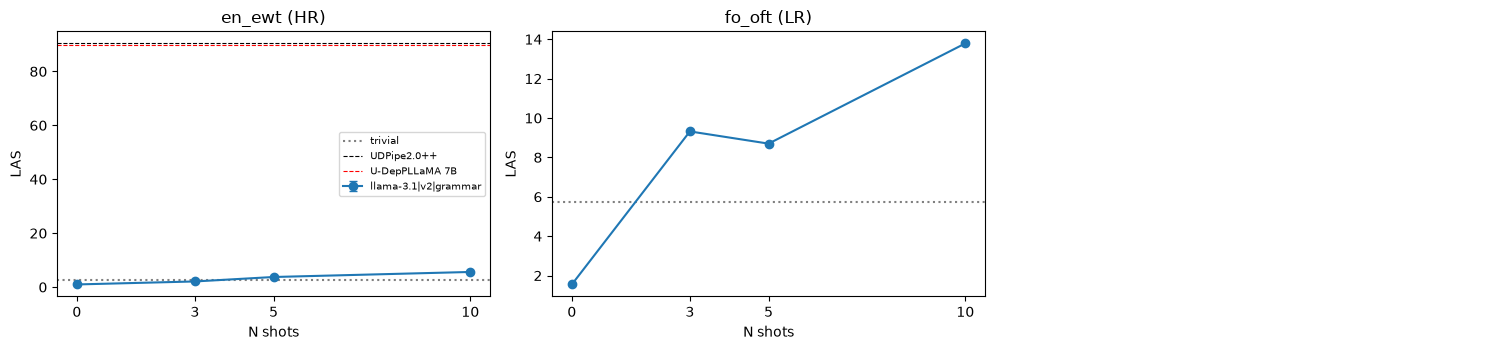

In [112]:
tbs = sorted(df.treebank.unique()); ncol = 3; nrow = math.ceil(len(tbs) / ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(5 * ncol, 3.6 * nrow), squeeze=False)
for ax, tb in zip(axes.flat, tbs):
    for m, g in agg[agg.treebank == tb].groupby("model"):
        ax.errorbar(g.N, g.LAS, yerr=g.LAS_sd.fillna(0), marker="o", capsize=3, label=m)
    ax.axhline(TRIVIAL[tb]["LAS"], ls=":", c="gray", label="trivial")
    if tb in REF: ax.axhline(REF[tb][0], ls="--", c="k", lw=.8, label="UDPipe2.0++"); ax.axhline(REF[tb][1], ls="--", c="r", lw=.8, label="U-DepPLLaMA 7B")
    ax.set_title(f"{tb} ({LEVEL[tb]})"); ax.set_xlabel("N shots"); ax.set_ylabel("LAS"); ax.set_xticks(sorted(df.N.unique()))
axes.flat[0].legend(fontsize=7)
for ax in list(axes.flat)[len(tbs):]: ax.axis("off")
plt.tight_layout(); plt.savefig(f"{CFG['out_dir']}/las_vs_shots.png", dpi=150); plt.show()

In [113]:
# Decision rule: weighted mean LAS over treebanks (LR languages weigh more), best N, and 0 -> max-shot slope
Nmax = agg.N.max()
best = agg[agg.N == Nmax].copy(); best["w"] = best.treebank.map(LEVEL).map(WEIGHT)
rank = (best.groupby("model").apply(lambda g: pd.Series({
            "wLAS@Nmax": np.average(g.LAS, weights=g.w), "wUAS@Nmax": np.average(g.UAS, weights=g.w),
            "invalid%": g.invalid.mean()})))
if 0 in agg.N.values:
    zero = agg[agg.N == 0].copy(); zero["w"] = zero.treebank.map(LEVEL).map(WEIGHT)
    z = zero.groupby("model").apply(lambda g: np.average(g.LAS, weights=g.w))
    rank["wLAS@0"] = z; rank["gain/shot"] = (rank["wLAS@Nmax"] - rank["wLAS@0"]) / Nmax
print(rank.sort_values("wLAS@Nmax", ascending=False).round(2))
print("\nCarry the top models forward to multilingual LoRA SFT. A steep gain/shot indicates latent syntactic ability.")

                      wLAS@Nmax  wUAS@Nmax  invalid%  wLAS@0  gain/shot
model                                                                  
llama-3.1|v2|grammar      11.06      15.76     47.25    1.36       0.97

Carry the top models forward to multilingual LoRA SFT. A steep gain/shot indicates latent syntactic ability.


## Notes
- **Ablations**: set `CFG["demo_source"]` (e.g. `{"bar_maibaam": "de_gsd", "fo_oft": "fo_farpahc"}`) for cross-lingual/cross-domain demonstrations; `CFG["mode"]="raw"` for end-to-end input (the model must tokenize; alignment is by word-form match, so $F_1$ differs from $\mathrm{LAS}$).
- **Context**: `demos_used` in the table shows the mean number of demonstrations that fit. Subword fragmentation of Faroese/Armenian/Bavarian can force it below $N$; this is a result, not a bug.
- **Bolmo / Aya**: check model ids and `trust_remote_code` support; byte-level models may need a different `max_new_tokens` budget (`run_batch` scales it by the *token* length of the gold tree).
- Push this notebook and `fewshot_ud/` result JSONs to GitHub.- **Prompt / constraint ablation**: `CFG["prompt"]` (`v1`, `v2`) and `CFG["constraint"]` (`none`, `grammar`, `grammar+words`) are part of the cache key and the aggregation label. Run `run_all()` once per combination (e.g. `CFG.update(prompt="v1", constraint="none")`).
- **`grammar` mode**: the output is a well-formed tree unless it is cut off by `max_new_tokens`; word omissions/duplicates are still repaired as in the paper (`recovered`). `grammar+words` removes these too, so the score isolates head and label choice.
- **v2 prompt** adds about 700 tokens; check `demos_used` at $N=10$ for 4k-context models.
